In [ ]:
import polars as pl
import matplotlib.pyplot as plt
from pathlib import Path
import polars as pl
import numpy as np
from matplotlib.patches import Patch
from procompa import get_project_root
from scipy import stats

PRJ_ROOT = get_project_root()
data_dir = PRJ_ROOT / "data"

In [ ]:
benchmark_metrics = pl.read_parquet(data_dir/ "Pipeline/18_CP_model_based_on_pae/cf_pdb_structure_similarity/cf_pdb_eval_all_metrics.parquet")
#add confidence
conf = {}
for d in {Path(p).parent for p in benchmark_metrics["combfold_output_path"]}:
    conf.update(dict(line.split() for line in open(d / "confidence.txt")))

benchmark_metrics = benchmark_metrics.with_columns(pl.col("combfold_output_path").map_elements(lambda p: float(conf[p]), return_dtype=pl.Float64).alias("CF_confidence"))

benchmark_best_cp  = benchmark_metrics.sort(pl.col("CF_confidence"), descending=True).group_by("complex_ac").first()
benchmark_best_cp_bigger = benchmark_best_cp.filter(pl.col("n_proteins") > 2)

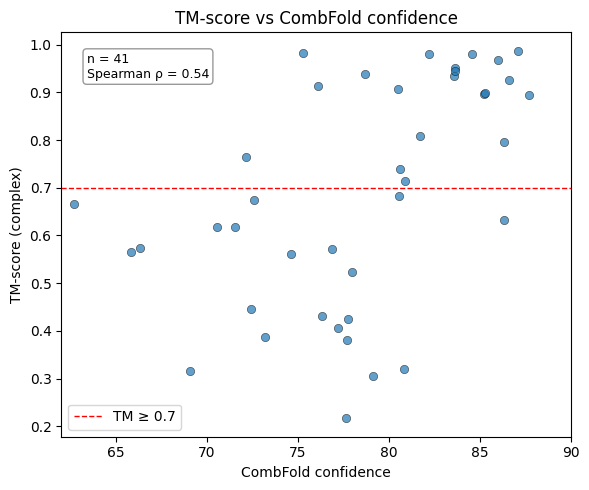

In [ ]:
#scatter plot of Tm score over the confidence
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(
    benchmark_best_cp_bigger["CF_confidence"],
    benchmark_best_cp_bigger["usalign_cpx_tm_score"],
    alpha=0.7, edgecolors="k", linewidths=0.4
)
ax.axhline(0.7, color="red", linestyle="--", linewidth=1, label="TM ≥ 0.7")
ax.set_xlabel("CombFold confidence")
ax.set_ylabel("TM-score (complex)")
ax.set_title("TM-score vs CombFold confidence")
ax.legend()

x = benchmark_best_cp_bigger["CF_confidence"].to_numpy()
y = benchmark_best_cp_bigger["usalign_cpx_tm_score"].to_numpy()
n = len(x)
spearman_r, spearman_p = stats.spearmanr(x, y)

ax.annotate(
    f"n = {n}\nSpearman ρ = {spearman_r:.2f}",
    xy=(0.05, 0.95), xycoords="axes fraction", va="top", fontsize=9,
    bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="gray", alpha=0.8)
)
plt.xlim(62, 90)
plt.tight_layout()
plt.show()

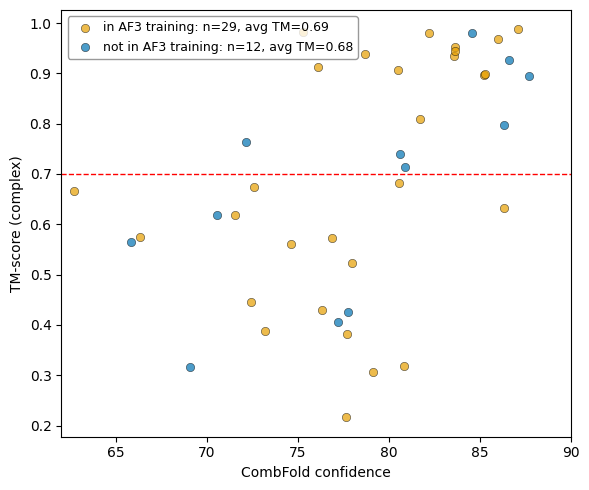

In [5]:
deposition_dates = pl.read_csv(
    "/cluster/project/beltrao/kdammer/master_thesis/data/complete_complex_pdb_mapping_v2/exact_pdb_match_deposition_dates.csv"
).select(["complex_ac", "Deposited before 2021-09-30"])

df = (
    benchmark_best_cp_bigger
    .join(deposition_dates, on="complex_ac", how="left")
)

fig, ax = plt.subplots(figsize=(6, 5))

colors = {"in_training": "#E69F00", "post_training": "#0072B2"}

for flag, color in [(True, colors["in_training"]), (False, colors["post_training"])]:
    sub = df.filter(pl.col("Deposited before 2021-09-30") == flag)
    n = len(sub)
    mean_tm = sub["usalign_cpx_tm_score"].mean()
    label = f"{'in' if flag else 'not in'} AF3 training: n={n}, avg TM={mean_tm:.2f}"
    ax.scatter(
        sub["CF_confidence"],
        sub["usalign_cpx_tm_score"],
        alpha=0.7, edgecolors="k", linewidths=0.4,
        color=color, zorder=3, label=label
    )

ax.axhline(0.7, color="red", linestyle="--", linewidth=1)

ax.set_xlabel("CombFold confidence")
ax.set_ylabel("TM-score (complex)")
#ax.set_title("TM-score vs CombFold confidence\n(color = AF3 training data status)")

ax.legend(
    fontsize=9, loc="upper left",
    framealpha=0.8, edgecolor="gray",
    handletextpad=0.4
)

plt.xlim(62, 90)
plt.tight_layout()
plt.show()

In [6]:
df.group_by("Deposited before 2021-09-30").agg(
    pl.col("usalign_cpx_tm_score").median().alias("median_tm"),
    pl.col("usalign_cpx_tm_score").mean().alias("mean_tm"),
    pl.len().alias("n"),
).sort("Deposited before 2021-09-30", descending=True)

Deposited before 2021-09-30,median_tm,mean_tm,n
bool,f64,f64,u32
true,0.67476,0.693134,29
false,0.72699,0.678881,12


In [7]:
# how many of the complexes od i keep, hoq many have  tM over 0.7  and waht is the fraction
# 2. For each confidence threshold: n complexes kept, n with TM ≥ 0.7, fraction
thresholds = np.arange(0, 100, 5)

rows = []
for t in thresholds:
    kept = benchmark_best_cp_bigger.filter(pl.col("CF_confidence") >= t)
    n_kept = len(kept)
    n_good = kept.filter(pl.col("usalign_cpx_tm_score") >= 0.7).height
    rows.append({"threshold": t, "n_kept": n_kept, "n_tm_good": n_good, "fraction": n_good / n_kept if n_kept > 0 else None})

summary = pl.DataFrame(rows)
print(summary)

shape: (20, 4)
┌───────────┬────────┬───────────┬──────────┐
│ threshold ┆ n_kept ┆ n_tm_good ┆ fraction │
│ ---       ┆ ---    ┆ ---       ┆ ---      │
│ i64       ┆ i64    ┆ i64       ┆ f64      │
╞═══════════╪════════╪═══════════╪══════════╡
│ 0         ┆ 41     ┆ 20        ┆ 0.487805 │
│ 5         ┆ 41     ┆ 20        ┆ 0.487805 │
│ 10        ┆ 41     ┆ 20        ┆ 0.487805 │
│ 15        ┆ 41     ┆ 20        ┆ 0.487805 │
│ 20        ┆ 41     ┆ 20        ┆ 0.487805 │
│ …         ┆ …      ┆ …         ┆ …        │
│ 75        ┆ 30     ┆ 19        ┆ 0.633333 │
│ 80        ┆ 19     ┆ 16        ┆ 0.842105 │
│ 85        ┆ 8      ┆ 7         ┆ 0.875    │
│ 90        ┆ 0      ┆ 0         ┆ null     │
│ 95        ┆ 0      ┆ 0         ┆ null     │
└───────────┴────────┴───────────┴──────────┘


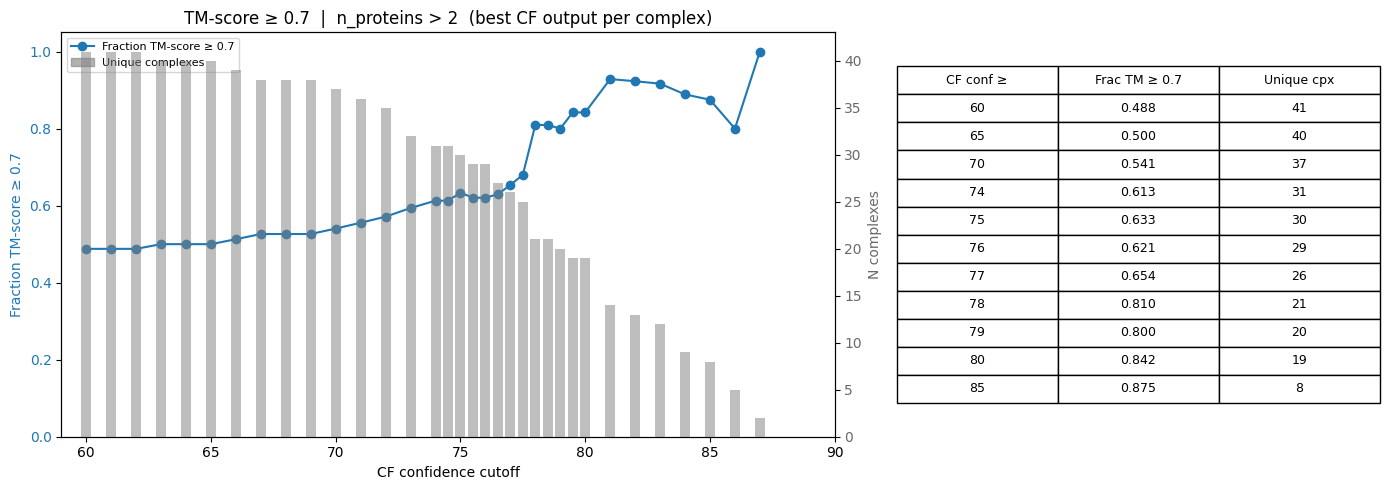

In [8]:
TM_TARGET = 0.7
benchmark_best_cp_bigger = benchmark_best_cp.filter(pl.col("n_proteins") > 2)

def precision_vs_cutoff(df, metric_col, target, higher_is_better=True,
                        thresholds=np.arange(60, 90, 1)):
    rows = []
    for t in thresholds:
        sub = df.filter(pl.col('CF_confidence') >= t)
        n_out = len(sub)
        n_cpx = sub['complex_ac'].n_unique() if n_out > 0 else 0
        if n_out > 0:
            prec = float((sub[metric_col] >= target if higher_is_better
                          else sub[metric_col] <= target).mean())
        else:
            prec = None
        rows.append((t, prec, n_cpx, n_out))
    return rows

def add_plot(ax1, rows, ylabel, color):
    thresholds_v, precisions, n_complexes_v, n_outputs_v = zip(*rows)
    ax1.plot(thresholds_v, precisions, marker='o', color=color)
    ax1.set_xlabel('CF confidence cutoff')
    ax1.set_ylabel(ylabel, color=color)
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.set_ylim(0, 1.05)
    ax1.set_xlim(59, max(thresholds_v) + 1)
    ax2 = ax1.twinx()
    ax2.bar(thresholds_v, n_complexes_v, alpha=0.5, color='tab:grey', width=0.4)
    ax2.set_ylabel('N complexes', color='dimgray')
    ax2.tick_params(axis='y', labelcolor='dimgray')
    ax1.legend(handles=[
        plt.Line2D([0],[0], marker='o', color=color, label=ylabel),
        Patch(color='tab:grey', alpha=0.6, label='Unique complexes'),
    ], loc='upper left', fontsize=8)

def add_table(ax, rows, frac_label):
    lookup = {r[0]: r for r in rows}  # float keys
    cols = ['CF conf ≥', frac_label, 'Unique cpx']
    cells = []
    for t in [60, 65, 70, 74, 75, 76, 77, 78, 79, 80, 85]:
        r = lookup.get(t) or lookup.get(float(t))
        if r:
            prec = f'{r[1]:.3f}' if r[1] is not None else 'nan'
            cells.append([str(t), prec, str(r[2])])
    ax.axis('off')
    tab = ax.table(cellText=cells, colLabels=cols, cellLoc='center', loc='center')
    tab.auto_set_font_size(False)
    tab.set_fontsize(9)
    tab.scale(1, 1.6)

thresholds = np.concatenate([
    np.arange(60, 74, 1),
    np.arange(74, 80, 0.5),
    np.arange(80, 90, 1),
])

rows_tm = precision_vs_cutoff(benchmark_best_cp_bigger, 'usalign_cpx_tm_score', TM_TARGET,
                               thresholds=thresholds)

fig, (ax_plot, ax_tab) = plt.subplots(1, 2, figsize=(14, 5),
                                       gridspec_kw={'width_ratios': [1.6, 1]})
add_plot(ax_plot, rows_tm, f'Fraction TM-score ≥ {TM_TARGET}', 'tab:blue')
ax_plot.set_title(f'TM-score ≥ {TM_TARGET}  |  n_proteins > 2  (best CF output per complex)')
add_table(ax_tab, rows_tm, f'Frac TM ≥ {TM_TARGET}')
fig.tight_layout()
plt.show()

stacked barplot

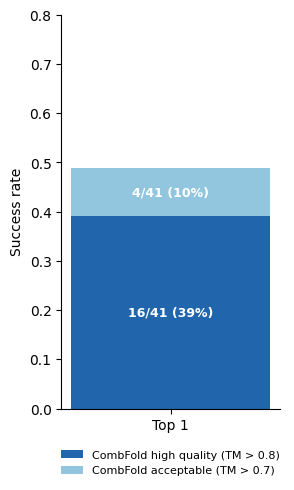

In [9]:
barplot_stacked_df = benchmark_best_cp_bigger.select(["complex_ac","usalign_cpx_tm_score"]) 
BLUE  = "#2166AC"   # high quality — bottom
LBLUE = "#92C5DE"   # acceptable — top

df = barplot_stacked_df
n   = df.height
hq  = (df["usalign_cpx_tm_score"] > 0.8).sum()
acc = (df["usalign_cpx_tm_score"] > 0.7).sum() - hq

hq_frac  = hq  / n
acc_frac = acc / n

fig, ax = plt.subplots(figsize=(3, 5))

ax.bar([0], [hq_frac],                    width=0.5, color=BLUE,  label="CombFold high quality (TM > 0.8)")
ax.bar([0], [acc_frac], bottom=[hq_frac], width=0.5, color=LBLUE, label="CombFold acceptable (TM > 0.7)")

ax.text(0, hq_frac / 2,             f"{hq}/{n} ({hq_frac:.0%})",   ha="center", va="center", fontsize=9, color="white", fontweight="bold")
ax.text(0, hq_frac + acc_frac / 2,  f"{acc}/{n} ({acc_frac:.0%})", ha="center", va="center", fontsize=9, color="white", fontweight="bold")

ax.set_xticks([0])
ax.set_xticklabels(["Top 1"])
ax.set_ylabel("Success rate")
ax.set_ylim(0, 0.8)
ax.spines[["top", "right"]].set_visible(False)

ax.legend(
    loc="upper center",
    bbox_to_anchor=(0.5, -0.08),
    frameon=False,
    fontsize=8,
    ncol=1,
)

plt.tight_layout()

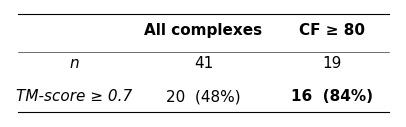

In [10]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines
import polars as pl
df = benchmark_best_cp_bigger

cf = df['CF_confidence'].to_numpy()
tm = df['usalign_cpx_tm_score'].to_numpy()

n_all       = len(cf)
n_all_good  = (tm >= 0.7).sum()
n_cf80      = (cf >= 80).sum()
n_cf80_good = ((cf >= 80) & (tm >= 0.7)).sum()

plt.rcParams.update({'font.family': 'sans-serif', 'font.size': 11})

col_labels = ['', 'All complexes', 'CF ≥ 80']
rows = [
    ['n',              str(n_all), str(n_cf80)],
    ['TM-score ≥ 0.7', f'{n_all_good}  ({100*n_all_good//n_all}%)', f'{n_cf80_good}  ({100*n_cf80_good//n_cf80}%)'],
]

fig, ax = plt.subplots(figsize=(4.2, 1.4))
ax.axis('off')

tbl = ax.table(cellText=rows, colLabels=col_labels, loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(11)
tbl.scale(1, 2.0)

for (i, j), cell in tbl.get_celld().items():
    cell.set_facecolor('none')
    cell.set_edgecolor('none')

for j in range(3):
    tbl[0, j].get_text().set_fontweight('bold')
for i in range(1, 3):
    tbl[i, 0].get_text().set_fontstyle('italic')
tbl[2, 2].get_text().set_fontweight('bold')

for y, lw in [(0.96, 0.8), (0.61, 0.4), (0.05, 0.8)]:
    ax.add_line(mlines.Line2D([0.02, 0.98], [y, y], transform=ax.transAxes,
                              color='black', linewidth=lw))
plt.tight_layout()
